# Online dependence estimation — experiment analysis

Loads the `experiment_<scenario>.csv` files produced by the C++ harness and plots each
estimator's tracking of the true Spearman's rho, plus an RMSE summary.

**Prerequisites** (run in a terminal from the repo root first):
```bash
pip install pandas matplotlib numpy jupyter
make experiment
for s in constant drift jump stochastic oscillate; do ./experiment $s; done
```
Then run this notebook top to bottom.

## Estimator configs (offline == online)

The offline harness (`src/estimators/registry.hpp`) and the live server
(`src/device/dependence_monitor.hpp`) now use **identical** estimator settings, so offline and
live RMSE are directly comparable. Memory is what matters; the `lambda` knob is mirror-imaged
between the two families (same effective memory, opposite direction):

| estimator | config | forgetting | effective memory (ESS) |
|---|---|---|---|
| `xiao` | bins 20, calibration 100 | lambda=0 (cumulative) | all history |
| `xiao_ew` | bins 20, calibration 100 | lambda=0.99 (retention: larger=longer) | ~200 ticks |
| `hermite` | order 10, burn-in 50 | lambda=0 (cumulative) | all history |
| `hermite_ew` | order 10, burn-in 50 | lambda=0.01 (update weight: smaller=longer) | ~100 ticks |

So `xiao_ew` (lambda 0.99) and `hermite_ew` (lambda 0.01) look like opposite numbers but both mean
"forget over ~100-200 ticks". lambda=0 means no forgetting (cumulative).

**Schedule note:** offline `oscillate` uses the same period (400) as the live server, so those are
directly comparable. Offline `drift`/`jump` run for N=5000 with a long constant tail, so they are
*not* length-matched to a ~1500-tick live capture — compare shapes, not absolute RMSE, there.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the repo root by walking up from the kernel's cwd until we hit the folder
# holding the Makefile + src/, so it works no matter where Jupyter launched.
def _find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for d in [p, *p.parents]:
        if (d / 'Makefile').exists() and (d / 'src').is_dir():
            return d
    return p  # fallback: kernel cwd

REPO = _find_repo_root()
# Experiment outputs (CSVs + PNGs) live in this experiment's results/ folder.
DATA_DIR = str(REPO / 'experiments' / 'results')
SCENARIOS = ['constant', 'drift', 'jump', 'stochastic', 'oscillate']
BURN_IN = 500  # steps to skip before scoring, matches the C++ harness

# Consistent colours across scenarios (match the C++/React client).
COLORS = {
    'xiao': '#ffb800',
    'xiao_ew': '#ff5555',
    'hermite': '#22d3ee',
    'hermite_ew': '#a78bfa',
    'windowed_rank': '#888888',
}
print('reading results from:', DATA_DIR)
found = [s for s in SCENARIOS if os.path.exists(os.path.join(DATA_DIR, f'experiment_{s}.csv'))]
print('offline CSVs found for:', found or 'none — run ./experiment <scenario> from the repo root first')

In [16]:
def load(scenario):
    path = os.path.join(DATA_DIR, f'experiment_{scenario}.csv')
    return pd.read_csv(path)

def estimator_cols(df):
    return [c for c in df.columns if c not in ('t', 'tick', 'true_rho_s')]

def plot_scenario(scenario):
    df = load(scenario)
    plt.figure(figsize=(11, 4.5))
    plt.plot(df['t'], df['true_rho_s'], color='black', lw=2.4, label='true rho_S')
    for col in estimator_cols(df):
        plt.plot(df['t'], df[col], lw=1.1, alpha=0.85,
                 color=COLORS.get(col), label=col)
    plt.axvline(BURN_IN, color='grey', ls=':', lw=1, label=f'burn-in ({BURN_IN})')
    plt.xlabel('t'); plt.ylabel('Spearman rho'); plt.ylim(-1, 1)
    plt.title(f'Online dependence tracking — {scenario}')
    plt.legend(loc='best', fontsize=8, ncol=2); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def rmse_table(scenario):
    df = load(scenario)
    tail = df[df['t'] >= BURN_IN]
    err = {c: float(np.sqrt(np.mean((tail[c] - tail['true_rho_s']) ** 2)))
           for c in estimator_cols(df)}
    return pd.Series(err, name=scenario)

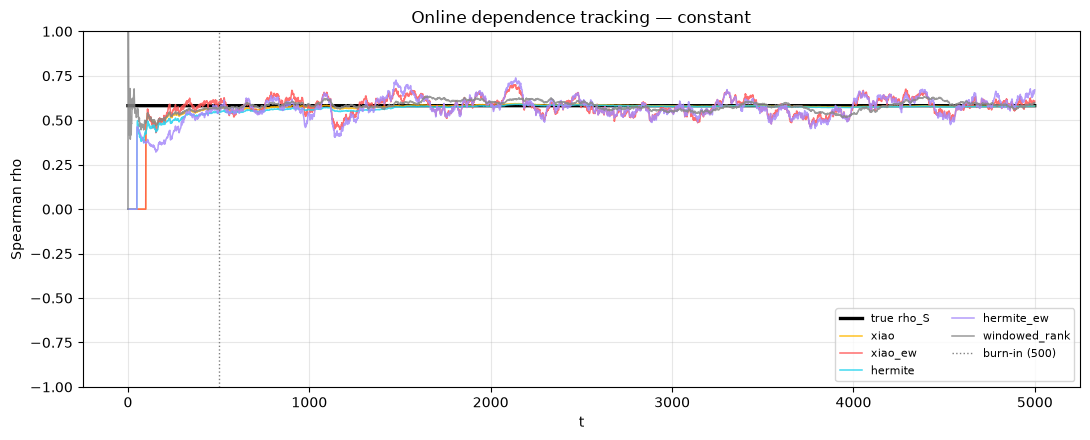

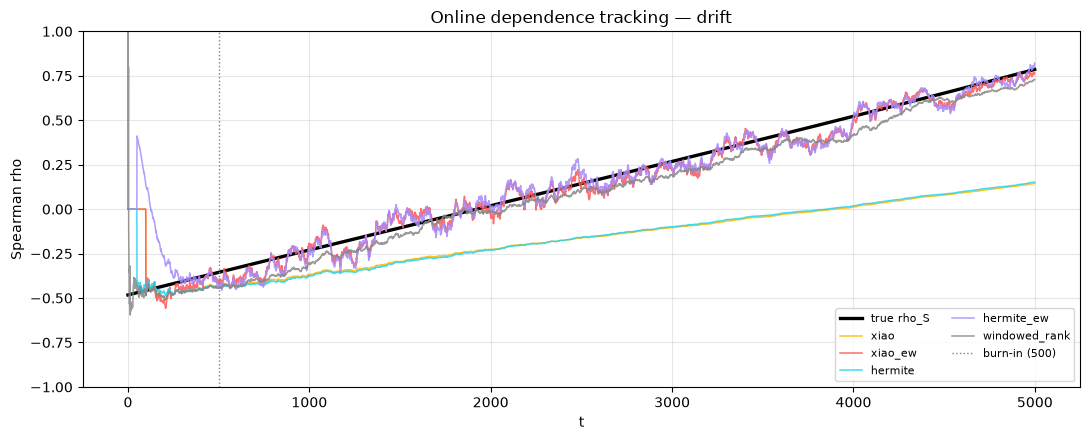

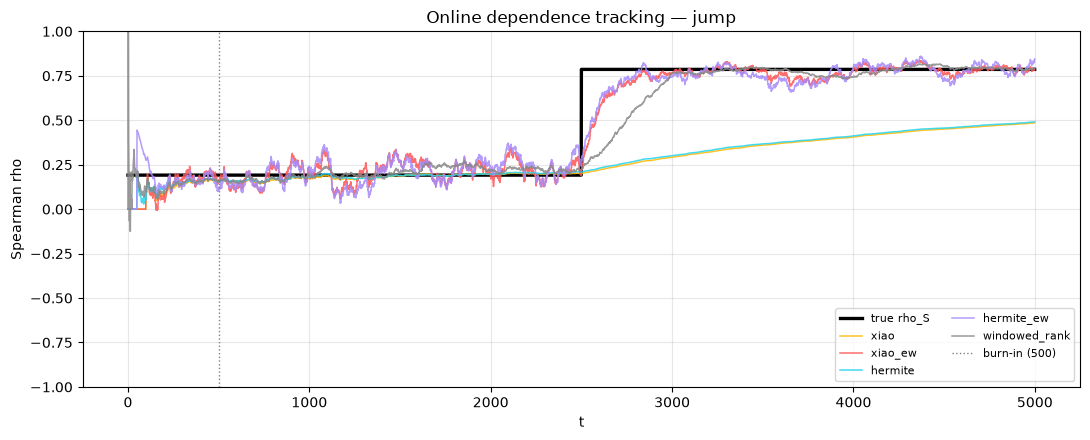

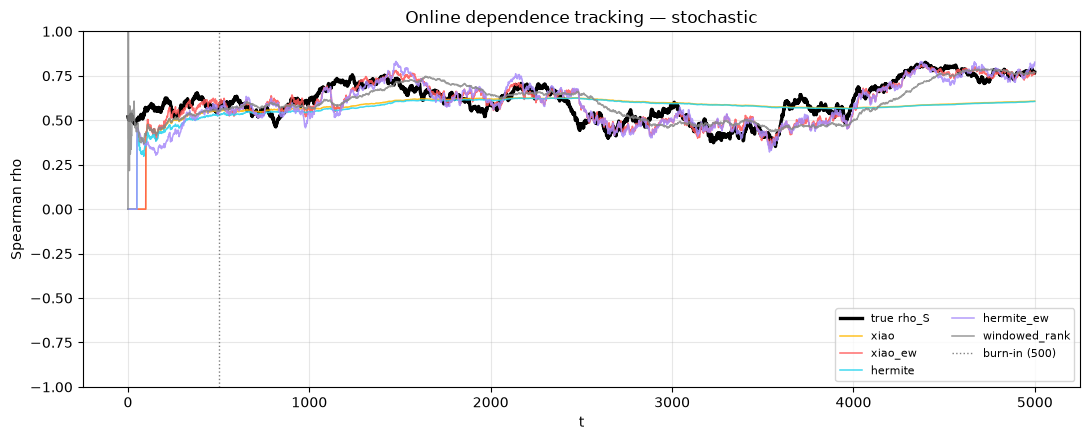

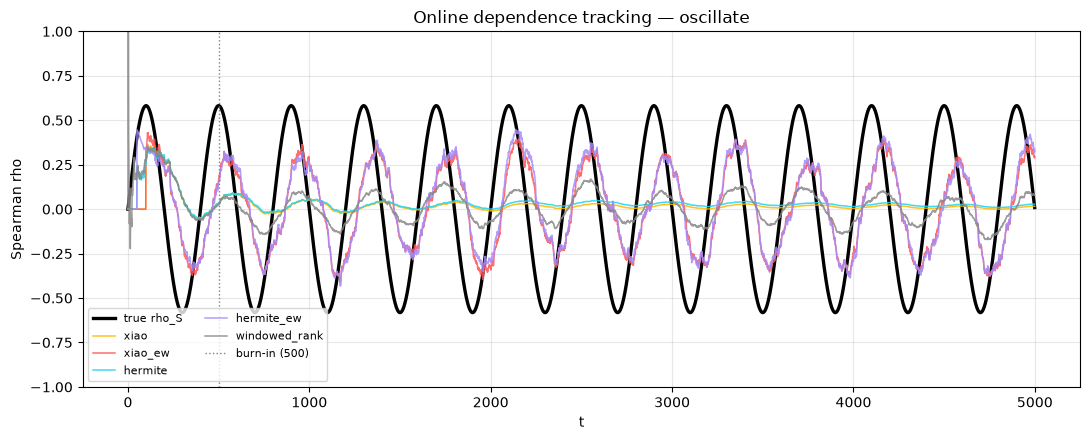

In [17]:
# Tracking plots, one per scenario.
for s in SCENARIOS:
    try:
        plot_scenario(s)
    except FileNotFoundError:
        print(f'missing experiment_{s}.csv — run ./experiment {s} first')

In [18]:
# RMSE vs true Spearman (after burn-in): rows = estimators, cols = scenarios.
rows = []
for s in SCENARIOS:
    try:
        rows.append(rmse_table(s))
    except FileNotFoundError:
        print(f'missing experiment_{s}.csv — skipping')
summary = pd.concat(rows, axis=1) if rows else pd.DataFrame()
summary.style.format('{:.4f}').background_gradient(cmap='RdYlGn_r', axis=None) if not summary.empty else summary

,constant,drift,jump,stochastic,oscillate
xiao,0.0071,0.3843,0.3147,0.1135,0.4096
xiao_ew,0.0451,0.0550,0.0782,0.0559,0.3426
hermite,0.0130,0.3813,0.3091,0.1155,0.4101
hermite_ew,0.0519,0.0581,0.0798,0.0611,0.3445
windowed_rank,0.0239,0.0660,0.1142,0.0749,0.3607


## Live probe captures

Plots captures from `live_probe.py --csv <file>` (the live server stream). Columns are
`tick, true_rho_s, <estimators>`.

Produce captures per schedule (the server picks the regime from the `DEPENDENCE` env var):
```bash
DEPENDENCE=constant ./server &   # in another terminal; also try drift / oscillate
python experiments/live_probe.py --csv experiments/results/live_constant.csv
```
The cell below auto-discovers every `live*.csv` in this experiment's `results/` folder, plots
each, and prints a metrics table (RMSE / bias / correlation / lag). `lag` is blank for a constant
truth — it is undefined when the target does not move.

In [ ]:
import glob

LIVE_WARMUP = 120  # skip estimator warm-up (xiao calibration ~100) when scoring

def _xcorr_lag(truth, est, maxlag=80):
    """Ticks the estimator trails the truth (argmax cross-correlation).
    None if the truth barely moves (lag is undefined for a constant target)."""
    truth = np.asarray(truth, float); est = np.asarray(est, float)
    n = len(truth)
    if n < 20 or truth.std() < 1e-3:
        return None
    best_k, best_c = 0, -2.0
    for k in range(maxlag + 1):
        if n - k < 10:
            break
        a, b = truth[:n - k], est[k:]
        if a.std() == 0 or b.std() == 0:
            continue
        c = np.corrcoef(a, b)[0, 1]
        if c > best_c:
            best_c, best_k = c, k
    return best_k

def plot_live(df, title=''):
    x = 'tick' if 'tick' in df.columns else 't'
    plt.figure(figsize=(11, 4.5))
    plt.plot(df[x], df['true_rho_s'], color='black', lw=2.4, label='true rho_S')
    for col in estimator_cols(df):
        plt.plot(df[x], df[col], lw=1.2, alpha=0.85, color=COLORS.get(col), label=col)
    plt.xlabel(x); plt.ylabel('Spearman rho'); plt.ylim(-1, 1)
    plt.title(f'Live online dependence tracking — {title}')
    plt.legend(loc='best', fontsize=8, ncol=2); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def live_metrics(df, warmup=LIVE_WARMUP):
    x = 'tick' if 'tick' in df.columns else 't'
    w = df[df[x] > warmup]
    truth = w['true_rho_s']
    out = {}
    for c in estimator_cols(df):
        err = w[c] - truth
        lag = _xcorr_lag(truth, w[c])
        out[c] = {
            'rmse': float(np.sqrt((err ** 2).mean())),
            'bias': float(err.mean()),
            'corr': float(np.corrcoef(w[c], truth)[0, 1]) if truth.std() > 0 else np.nan,
            'lag': (np.nan if lag is None else float(lag)),
        }
    return pd.DataFrame(out).T

# Plot every live*.csv capture in this experiment's results/ folder, with a metrics table each.
live_files = sorted(glob.glob(os.path.join(DATA_DIR, 'live*.csv')))
if not live_files:
    print('no live*.csv found — capture one with: '
          'python experiments/live_probe.py --csv experiments/results/live_<schedule>.csv')
for path in live_files:
    name = os.path.basename(path)
    df = pd.read_csv(path)
    print(f'=== {name}  ({len(df)} ticks) ===')
    plot_live(df, title=name)
    m = live_metrics(df).style.format({'rmse': '{:.4f}', 'bias': '{:+.4f}',
                                       'corr': '{:+.3f}', 'lag': '{:.0f}'})
    display(m)